# Module 03: Detector Fine-Tuning and Comparative Performance Analysis

**Objective.** This notebook fine-tunes a pretrained YOLO detector on MOT16 and quantifies the improvement over the pretrained baseline.

### Experimental Protocol

1. Restore the dataset produced in Notebook 02.
2. Evaluate the pretrained model on the validation sequence (MOT16-09) to establish a baseline.
3. Fine-tune the model on the training sequences, saving a checkpoint to Google Drive after each epoch so that training can resume after a disconnection.
4. Evaluate the fine-tuned model on the same validation sequence.
5. Analyze the training curves, qualitative detections, and the sensitivity of the detector to the confidence threshold.

**Key result.** The comparison between the pretrained and fine-tuned models on MOT16-09 (precision, recall, mAP@50, and mAP@50–95) is the primary detector result for the midterm presentation.

In [ ]:
# 1. Set up, path, and check train and test dataset
!pip -q install ultralytics
from pathlib import Path

CANDIDATES = [Path('/content/drive/MyDrive/MOT16_project/Backup'),
              Path('/content/drive/MyDrive/MOT16_project/DL_Video_Tracking ')]     # trailing space is intentional
BASE = next((p for p in CANDIDATES if (p/'yolo_mot16.zip').exists()), None)
assert BASE, 'yolo_mot16.zip not found on Drive - run notebook 02 (step 7) first'

OUT = Path('/content/yolo_mot16')
if not (OUT/'images'/'val').exists():
    import shutil; shutil.unpack_archive(str(BASE/'yolo_mot16.zip'), '/content')
# the yaml stores an absolute path; rewrite it so it is correct in this session
yaml_path = OUT/'data.yaml'
yaml_path.write_text(f'path: {OUT}\ntrain: images/train\nval: images/val\nnames:\n  0: person\n')
print('train imgs:', len(list((OUT/'images'/'train').glob('*.jpg'))),
      '| val imgs:', len(list((OUT/'images'/'val').glob('*.jpg'))))

RUNS = BASE/'runs'          # checkpoints live on Drive so a disconnect does not lose them
RUNS.mkdir(exist_ok=True)
RESULTS = BASE/'results'; RESULTS.mkdir(exist_ok=True)

train imgs: 2396 | val imgs: 525


In [ ]:
# 2. Config (change here, nowhere else)to check for GPU runtime
import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - set runtime to GPU')

WEIGHTS = 'yolo26m.pt'     # fallback: 'yolo11m.pt'. Use '...s.pt' if GPU memory/time is tight.
EPOCHS  = 30
IMGSZ   = 960              # MOT16 has small, distant pedestrians; 640 loses them
BATCH   = 8                # lower to 4 if CUDA out-of-memory
RUN_NAME = 'yolo_mot16_ft'

# Augmentation knobs (Ultralytics defaults are already on: mosaic, HSV colour jitter, horizontal flip).
# Change one at a time and keep a note - this is your 'played with the code' evidence.
AUG = dict(fliplr=0.5, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, scale=0.5, degrees=0.0, mosaic=1.0)

GPU: NVIDIA A100-SXM4-40GB


In [ ]:
# 3. BASELINE: pretrained COCO model on MOT16-09 (person class only)
from ultralytics import YOLO
pre = YOLO(WEIGHTS)
m0 = pre.val(data=str(yaml_path), imgsz=IMGSZ, batch=BATCH, classes=[0],
             conf=0.001, project=str(RUNS), name='val_pretrained', exist_ok=True, plots=False)
base = dict(P=m0.box.mp, R=m0.box.mr, mAP50=m0.box.map50, mAP50_95=m0.box.map)
print({k: round(float(v), 4) for k, v in base.items()})

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO26m summary (fused): 130 layers, 20,411,132 parameters, 0 gradients, 68.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2536.7±429.1 MB/s, size: 207.6 KB)
val: Scanning /content/yolo_mot16/labels/val... 525 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 525/525 1.4Kit/s 0.4s
val: New cache created: /content/yolo_mot16/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 66/66 15.3it/s 4.3s
                   all        525       5257      0.904      0.728      0.792      0.511
                person        525   

In [ ]:
# 4. FINE-TUNE. Safe to re-run after a Colab disconnect: it resumes from last.pt if one exists.
last = RUNS/RUN_NAME/'weights'/'last.pt'
if last.exists():
    print('Resuming from', last)
    model = YOLO(str(last))
    model.train(resume=True)
else:
    model = YOLO(WEIGHTS)
    model.train(data=str(yaml_path), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
                patience=10,                 # stop early if val mAP stalls for 10 epochs
                project=str(RUNS), name=RUN_NAME, exist_ok=True,
                workers=2, cos_lr=True, seed=42, plots=True, **AUG)

Resuming from /content/drive/MyDrive/MOT16_project/Backup/runs/yolo_mot16_ft/weights/last.pt
WARNING ⚠️ model '/content/drive/MyDrive/MOT16_project/Backup/runs/yolo_mot16_ft/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5,

In [ ]:
# 5. FINE-TUNED model on the SAME validation sequence
best = RUNS/RUN_NAME/'weights'/'best.pt'
assert best.exists(), 'training has not produced best.pt yet'
ft = YOLO(str(best))
m1 = ft.val(data=str(yaml_path), imgsz=IMGSZ, batch=BATCH, conf=0.001,
            project=str(RUNS), name='val_finetuned', exist_ok=True, plots=False)
tuned = dict(P=m1.box.mp, R=m1.box.mr, mAP50=m1.box.map50, mAP50_95=m1.box.map)

import pandas as pd
table = pd.DataFrame({'pretrained': base, 'fine-tuned': tuned}).astype(float).round(4)
table['change'] = (table['fine-tuned'] - table['pretrained']).round(4)
display(table)
table.to_csv(RESULTS/'detector_pretrained_vs_finetuned.csv')

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO26m summary (fused): 130 layers, 20,350,223 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3182.6±1034.4 MB/s, size: 201.7 KB)
val: Scanning /content/yolo_mot16/labels/val.cache... 525 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 525/525 157.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 66/66 16.0it/s 4.1s
                   all        525       5257      0.905       0.78      0.872      0.591
Speed: 0.8ms preprocess, 3.5ms inference, 0.0ms loss, 0.8ms postprocess per image


,pretrained,fine-tuned,change
P,0.9041,0.9053,0.0012
R,0.7282,0.7803,0.0521
mAP50,0.7921,0.8724,0.0803
mAP50_95,0.5110,0.5911,0.0801


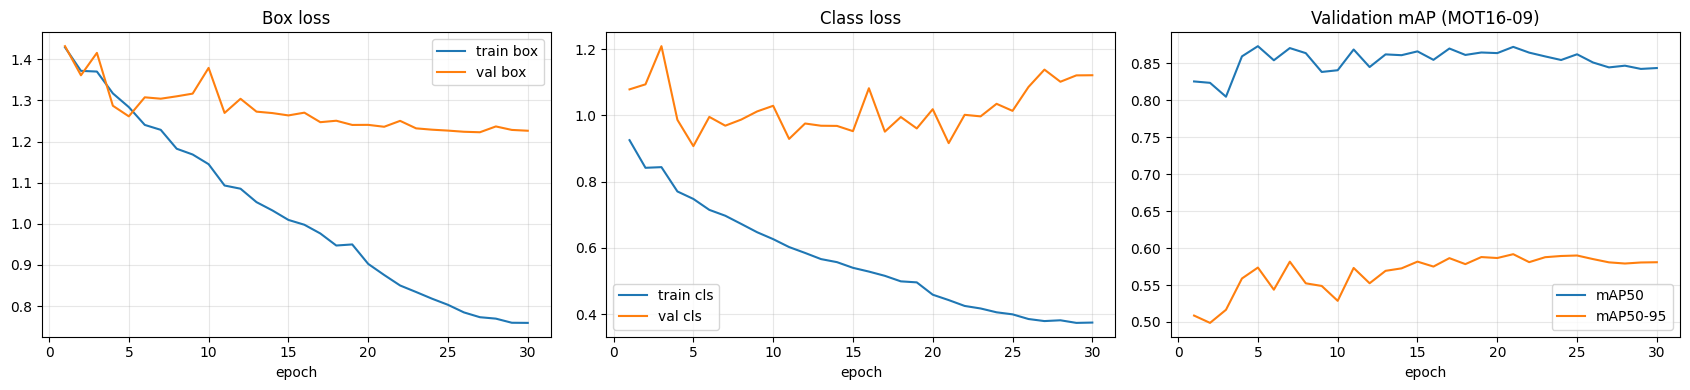

In [ ]:
# 6. Training curves
import matplotlib.pyplot as plt
df = pd.read_csv(RUNS/RUN_NAME/'results.csv'); df.columns = [c.strip() for c in df.columns]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(df['epoch'], df['train/box_loss'], label='train box'); ax[0].plot(df['epoch'], df['val/box_loss'], label='val box')
ax[0].set_title('Box loss'); ax[0].legend()
ax[1].plot(df['epoch'], df['train/cls_loss'], label='train cls'); ax[1].plot(df['epoch'], df['val/cls_loss'], label='val cls')
ax[1].set_title('Class loss'); ax[1].legend()
ax[2].plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP50'); ax[2].plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP50-95')
ax[2].set_title('Validation mAP (MOT16-09)'); ax[2].legend()
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS/'detector_training_curves.png', dpi=130); plt.show()

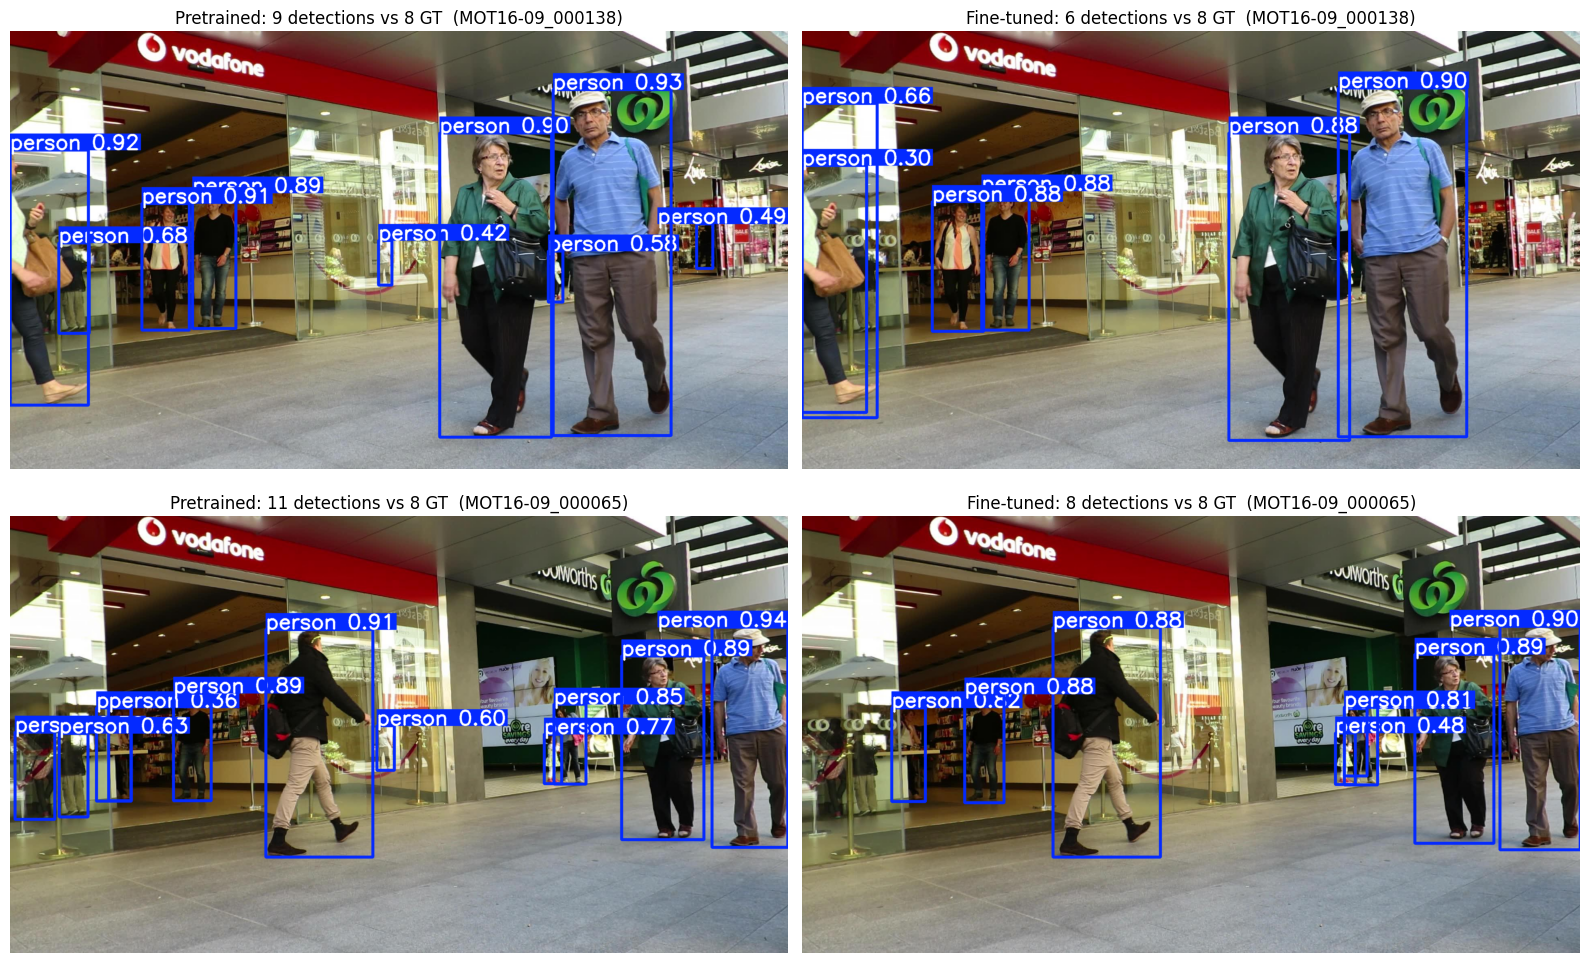

In [ ]:
# 7. Before / after on the same validation frames
import cv2, random
random.seed(1)
val_imgs = sorted((OUT/'images'/'val').glob('*.jpg'))
picks = random.sample(val_imgs, 2)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for row, p in zip(axes, picks):
    n_gt = len((OUT/'labels'/'val'/f'{p.stem}.txt').read_text().splitlines())
    for ax, mdl, title, kw in [(row[0], pre, 'Pretrained', dict(classes=[0])), (row[1], ft, 'Fine-tuned', {})]:
        r = mdl.predict(str(p), conf=0.25, imgsz=IMGSZ, verbose=False, **kw)[0]
        ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.axis('off')
        ax.set_title(f'{title}: {len(r.boxes)} detections vs {n_gt} GT  ({p.stem})')
plt.tight_layout(); plt.savefig(RESULTS/'detector_before_after.png', dpi=130); plt.show()

In [ ]:
# 9. Keep the weights on Drive for the tracking notebook (weights are NOT submitted, only code)
import shutil
shutil.copy(best, BASE/'yolo_mot16_best.pt')
print('saved', BASE/'yolo_mot16_best.pt')
print('results in', RESULTS)

saved /content/drive/MyDrive/MOT16_project/Backup/yolo_mot16_best.pt
results in /content/drive/MyDrive/MOT16_project/Backup/results
